# Introduction

<img src="assets/bricks.jpg" width="600">

Today we dive into a dataset all about LEGO. It answers questions about the history of the company, its product offering and which set rules them all:

<ul type="square">
<li><b>What is the most enormous LEGO set ever created and how many parts did it have?</b></li>
<li><b>In which year were the first LEGO sets released and how many sets did the company sell when it first launched?</b></li>
<li><b>Which LEGO theme has the most sets?</b></li>
<li><b>When did the company really take off? How many themes and sets did it release every year?</b></li>
<li><b>Did LEGO sets grow in size and complexity over time?</b></li>
</ul>

The analysis functions live in the tested package <code>lego_analysis</code>; this notebook follows the lecture step by step and calls them.

## Answers at a glance

<ol>
<li><b>The most enormous LEGO set:</b> <i>The Ultimate Battle for Chima</i> (set BIGBOX-1, released 2015) with <b>9,987 parts</b>. The largest set you can actually buy is the UCS Millennium Falcon with 7,541 parts.</li>
<li><b>The first sets:</b> released in <b>1949</b>; LEGO sold only <b>5 sets</b> in its first year.</li>
<li><b>The theme with the most sets:</b> <b>Star Wars</b> with <b>753 sets</b>, ahead of Gear (656), Friends (398) and Ninjago (356).</li>
<li><b>When LEGO took off:</b> in the <b>mid-1990s</b>. Sets per year grew from 5 (1949) and 28 (1955) to 175 (1995) and 840 (2019); themes per year grew from 2 (1949) and 4 (1955) to 55 (1995) and 78 (2019).</li>
<li><b>Bigger and more complex?</b> <b>Yes.</b> The average set had about 12 parts in 1954 and about 222 parts in 2017.</li>
</ol>

# Import Statements

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from lego_analysis.application import analysis
from lego_analysis.infrastructure.data import load_colors, load_sets, load_themes

# Data Exploration

**Challenge**: How many different colours does the LEGO company produce? Read the <code>colors.csv</code> file in the data folder and find the total number of unique colours. Try the <a href="https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.nunique.html">.nunique() method</a>.

In [2]:
colors = load_colors()  # pd.read_csv('data/colors.csv')
colors.head()

,id,name,rgb,is_trans
0,-1,Unknown,0033B2,f
1,0,Black,05131D,f
2,1,Blue,0055BF,f
3,2,Green,237841,f
4,3,Dark Turquoise,008F9B,f


In [3]:
colors['name'].nunique()

135

**Challenge**: Find the number of transparent colours (<code>is_trans == 't'</code>) versus opaque colours (<code>is_trans == 'f'</code>) in two different ways.

In [4]:
colors.groupby('is_trans').count()

,id,name,rgb
is_trans,,,
f,107,107,107
t,28,28,28


In [5]:
colors.is_trans.value_counts()

is_trans
f    107
t     28
Name: count, dtype: int64

In [6]:
analysis.transparent_counts_groupby(colors) == analysis.transparent_counts_value_counts(colors)

True

### Understanding LEGO Themes vs. LEGO Sets

Walk into a LEGO store and you will see products organised by theme: Star Wars, Batman, Harry Potter and many more.

<img src="assets/lego_themes.png" width="600">

A LEGO set is a particular box of LEGO or product. A single theme typically has many different sets.

<img src="assets/lego_sets.png" width="600">

The <code>sets.csv</code> data lists the sets over the years and the number of parts of each. **Challenge**: read the data and look at the first and last rows.

In [7]:
sets = load_sets()
sets.head()

,set_num,name,year,theme_id,num_parts
0,001-1,Gears,1965,1,43
1,0011-2,Town Mini-Figures,1978,84,12
2,0011-3,Castle 2 for 1 Bonus Offer,1987,199,0
3,0012-1,Space Mini-Figures,1979,143,12
4,0013-1,Space Mini-Figures,1979,143,12


In [8]:
sets.tail()

,set_num,name,year,theme_id,num_parts
15705,wwgp1-1,Wild West Limited Edition Gift Pack,1996,476,0
15706,XMASTREE-1,Christmas Tree,2019,410,26
15707,XWING-1,Mini X-Wing Fighter,2019,158,60
15708,XWING-2,X-Wing Trench Run,2019,158,52
15709,YODACHRON-1,Yoda Chronicles Promotional Set,2013,158,413


**Challenge**: In which year were the first LEGO sets released and what were they called?

In [9]:
sets.sort_values('year').head()

,set_num,name,year,theme_id,num_parts
9545,700.B-1,Small Doors and Windows Set (ABB),1949,371,12
9521,700.1-1,Extra-Large Gift Set (ABB),1949,365,142
9539,700.3-1,Medium Gift Set (ABB),1949,365,142
9544,700.A-1,Small Brick Set (ABB),1949,371,24
9534,700.2-1,Large Gift Set (ABB),1949,365,178


**Challenge**: How many different sets did LEGO sell in their first year?

In [10]:
sets[sets['year'] == 1949]

,set_num,name,year,theme_id,num_parts
9521,700.1-1,Extra-Large Gift Set (ABB),1949,365,142
9534,700.2-1,Large Gift Set (ABB),1949,365,178
9539,700.3-1,Medium Gift Set (ABB),1949,365,142
9544,700.A-1,Small Brick Set (ABB),1949,371,24
9545,700.B-1,Small Doors and Windows Set (ABB),1949,371,12


In [11]:
analysis.count_sets_in_year(sets, 1949)

5

**Answer — the first sets:** the first LEGO sets were released in **1949** and the company sold **5 sets** in its first year.

**Challenge**: Find the top 5 LEGO sets with the most parts.

In [12]:
sets.sort_values('num_parts', ascending=False).head()

,set_num,name,year,theme_id,num_parts
15004,BIGBOX-1,The Ultimate Battle for Chima,2015,571,9987
11183,75192-1,UCS Millennium Falcon,2017,171,7541
10551,71043-1,Hogwarts Castle,2018,246,6020
295,10256-1,Taj Mahal,2017,673,5923
221,10189-1,Taj Mahal,2008,673,5922


**Answer — the most enormous LEGO set:** *The Ultimate Battle for Chima* (BIGBOX-1, 2015) has **9,987 parts**. Next comes the UCS Millennium Falcon with 7,541 parts, the largest regular retail set.

**Challenge**: Use <code>.groupby()</code> and <code>.count()</code> to show the number of sets released year-on-year.

In [13]:
sets_by_year = sets.groupby('year').count()
sets_by_year.head()

,set_num,name,theme_id,num_parts
year,,,,
1949,5,5,5,5
1950,6,6,6,6
1953,4,4,4,4
1954,14,14,14,14
1955,28,28,28,28


In [14]:
sets_by_year.set_num.loc[[1955, 2019]]

year
1955     28
2019    840
Name: set_num, dtype: int64

**Challenge**: Show the number of releases on a line chart. The .csv file is from late 2020, so exclude the last two (incomplete) years with list slicing.

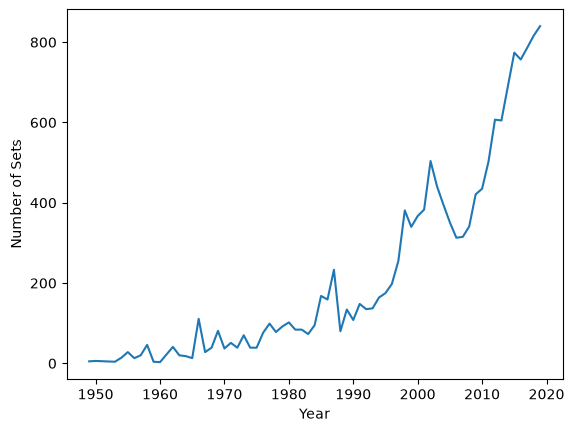

In [15]:
plt.plot(sets_by_year.index[:-2], sets_by_year.set_num[:-2])
plt.xlabel('Year')
plt.ylabel('Number of Sets')
plt.show()

### Aggregate Data with the Python .agg() Function

In [16]:
themes_by_year = sets.groupby('year').agg({'theme_id': 'nunique'})
themes_by_year.rename(columns={'theme_id': 'nr_themes'}, inplace=True)
themes_by_year.head()

C:\Users\jenst\AppData\Local\Temp\ipykernel_15780\1968533275.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  themes_by_year.rename(columns={'theme_id': 'nr_themes'}, inplace=True)


,nr_themes
year,
1949,2
1950,1
1953,2
1954,2
1955,4


**Challenge**: Plot the number of themes by year. Only include full calendar years.

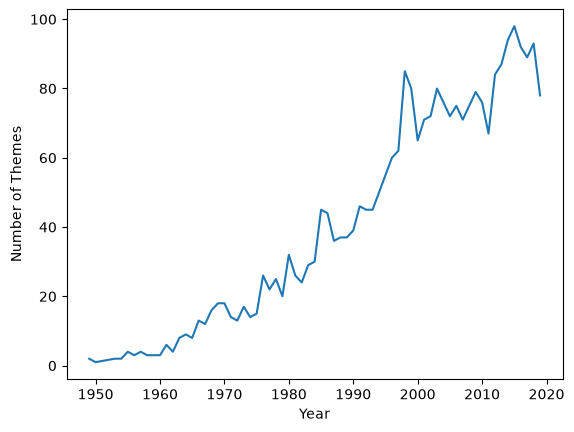

In [17]:
plt.plot(themes_by_year.index[:-2], themes_by_year.nr_themes[:-2])
plt.xlabel('Year')
plt.ylabel('Number of Themes')
plt.show()

**Answer — when LEGO took off:** LEGO grew slowly for its first 45 years and took off in the **mid-1990s**. Sets per year rose from 5 in 1949 and 28 in 1955 to 175 in 1995 and 840 in 2019; themes per year rose from 2 in 1949 and 4 in 1955 to 55 in 1995 and 78 in 2019. After 2005 the number of themes stalled until the early 2010s.

### Line Charts with Two Separate Axes

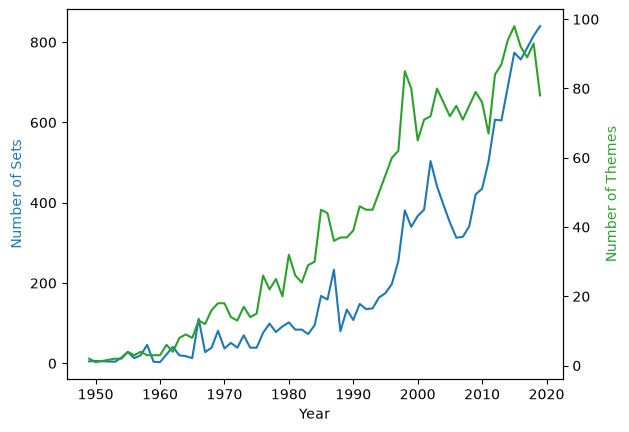

In [18]:
ax1 = plt.gca()  # get current axes
ax2 = ax1.twinx()
ax1.plot(sets_by_year.index[:-2], sets_by_year.set_num[:-2], color='tab:blue')
ax2.plot(themes_by_year.index[:-2], themes_by_year.nr_themes[:-2], color='tab:green')
ax1.set_xlabel('Year')
ax1.set_ylabel('Number of Sets', color='tab:blue')
ax2.set_ylabel('Number of Themes', color='tab:green')
plt.show()

**Challenge**: Use <code>.groupby()</code> and <code>.agg()</code> together to find the average number of parts per set. How many parts did the average set of 1954 have compared to 2017?

In [19]:
parts_per_set = sets.groupby('year').agg({'num_parts': 'mean'})
parts_per_set.loc[[1954, 2017]]

,num_parts
year,
1954,12.357143
2017,221.840967


### Scatter Plots in Matplotlib

**Challenge**: Has the size and complexity of LEGO sets increased over time? Plot the average number of parts with a scatter plot.

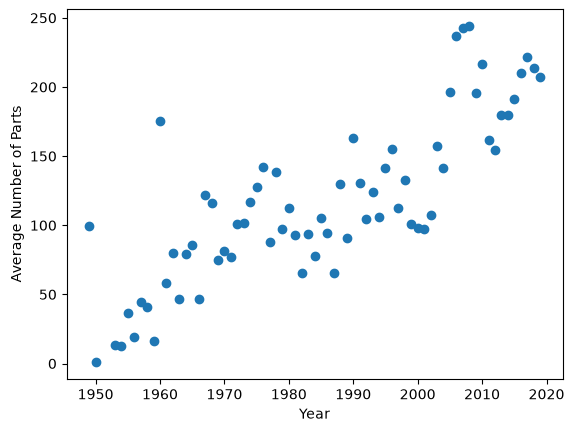

In [20]:
plt.scatter(parts_per_set.index[:-2], parts_per_set.num_parts[:-2])
plt.xlabel('Year')
plt.ylabel('Average Number of Parts')
plt.show()

**Answer — bigger and more complex?** Yes. The average set had about **12 parts in 1954** and about **222 parts in 2017**; the scatter plot shows a clear upward trend.

### Number of Sets per LEGO Theme

LEGO has licensed many hit franchises, from Harry Potter to Marvel Super Heroes. Which theme has the most sets?

In [21]:
set_theme_count = sets['theme_id'].value_counts()
set_theme_count.head()

theme_id
158    753
501    656
494    398
435    356
503    329
Name: count, dtype: int64

### Database Schemas, Foreign Keys and Merging DataFrames

<img src="assets/rebrickable_schema.png" width="700">

The <code>themes.csv</code> file has the theme names. The sets table has <code>theme_id</code> (a foreign key) that links to the <code>id</code> column of the themes table (its primary key).

**Challenge**: Explore <code>themes.csv</code>. Search for the name 'Star Wars'. How many ids correspond to this name? Find the corresponding sets.

In [22]:
themes = load_themes()
themes.head()

,id,name,parent_id
0,1,Technic,NaN
1,2,Arctic Technic,1.0
2,3,Competition,1.0
3,4,Expert Builder,1.0
4,5,Model,1.0


In [23]:
themes[themes.name == 'Star Wars']

,id,name,parent_id
17,18,Star Wars,1.0
150,158,Star Wars,NaN
174,209,Star Wars,207.0
211,261,Star Wars,258.0


In [24]:
sets[sets.theme_id == 18]

,set_num,name,year,theme_id,num_parts
8786,65081-1,R2-D2 / C-3PO Droid Collectors Set,2002,18,1
12051,8000-1,Pit Droid,2000,18,223
12058,8001-1,Battle Droid,2000,18,336
12066,8002-1,Destroyer Droid,2000,18,567
12071,8007-1,C-3PO,2001,18,339
12072,8008-1,Stormtrooper,2001,18,360
12073,8009-1,R2-D2,2002,18,239
12074,8010-1,Darth Vader,2002,18,388
12081,8011-1,Jango Fett,2002,18,425
12083,8012-1,Super Battle Droid,2002,18,378


In [25]:
sets[sets.theme_id == 209]

,set_num,name,year,theme_id,num_parts
11013,75023-1,Star Wars Advent Calendar 2013,2013,209,254
11046,75056-1,Star Wars Advent Calendar 2014,2014,209,273
11080,75097-1,Star Wars Advent Calendar 2015,2015,209,291
11131,75146-1,Star Wars Advent Calendar 2016,2016,209,282
11173,75184-1,Star Wars Advent Calendar 2017,2017,209,309
11206,75213-1,Star Wars Advent Calendar 2018,2018,209,307
11245,75245-1,Star Wars Advent Calendar 2019,2019,209,280
11281,75279-1,Star Wars Advent Calendar 2020,2020,209,312
12019,7958-1,Star Wars Advent Calendar 2011,2011,209,267
14352,9509-1,Star Wars Advent Calendar 2012,2012,209,235


### Merging (i.e., Combining) DataFrames based on a Key

In [26]:
set_theme_count = pd.DataFrame({'id': set_theme_count.index, 'set_count': set_theme_count.values})
set_theme_count.head()

,id,set_count
0,158,753
1,501,656
2,494,398
3,435,356
4,503,329


In [27]:
merged_df = pd.merge(set_theme_count, themes, on='id')
merged_df[:3]

,id,set_count,name,parent_id
0,158,753,Star Wars,NaN
1,501,656,Gear,NaN
2,494,398,Friends,NaN


**Answer — the theme with the most sets:** **Star Wars** (theme id 158) leads with **753 sets**, followed by Gear (656), Friends (398) and Ninjago (356).

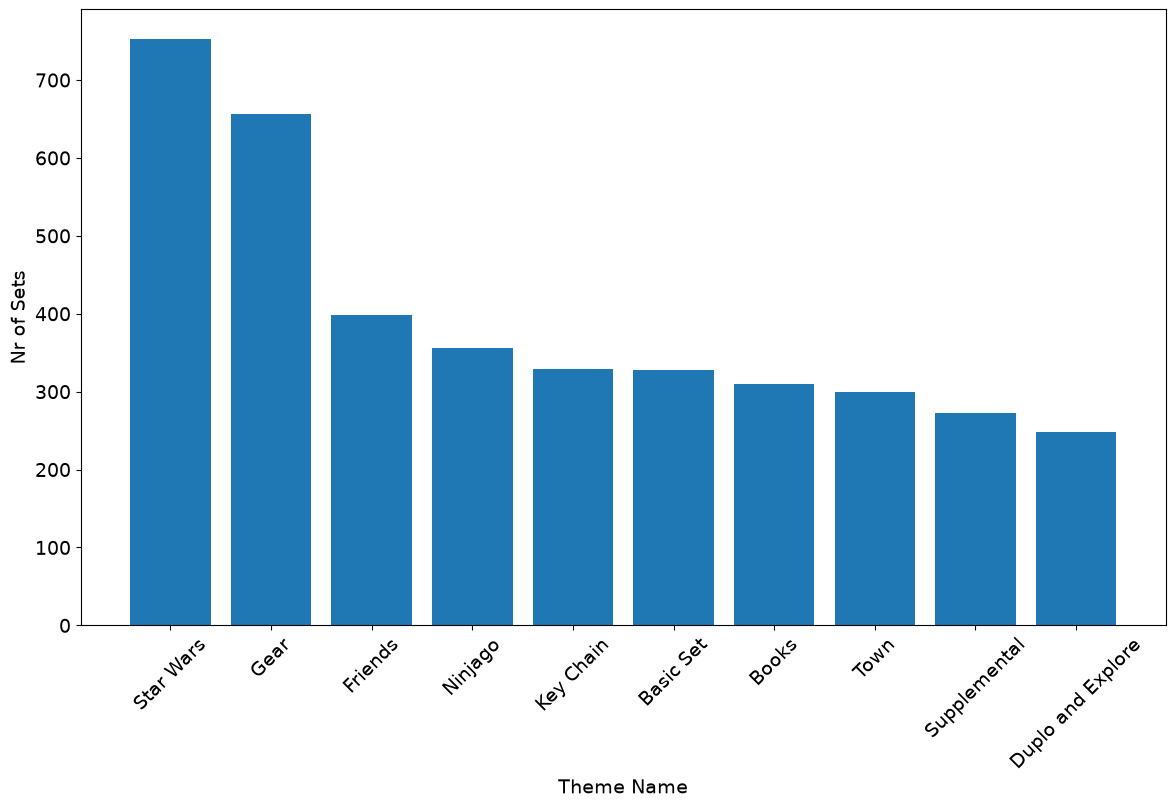

In [28]:
plt.figure(figsize=(14, 8))
plt.xticks(fontsize=14, rotation=45)
plt.yticks(fontsize=14)
plt.ylabel('Nr of Sets', fontsize=14)
plt.xlabel('Theme Name', fontsize=14)
plt.bar(merged_df.name[:10], merged_df.set_count[:10])
plt.show()